In [2]:
import numpy as np
import pandas as pd
import xsim
import xtools as xt
import matplotlib.pyplot as plt
from pyqubo import Array, Constraint
from openjij import SQASampler, SASampler
from typing import Callable, Dict, List

from atm.flight.generator import ScenarioGenerator
from atm.optimizer.objective import get_obj_single_runway, calc_assign_time
from atm.separation import recat, faa

In [3]:
cf = xt.Config(dict(
    num=10,
    scenario=dict(
        interval=60,
        window=200,
        mode="mix",
        standard="recat",
        seed=0,
    ),
    penalty_coef=10,
))
sep = recat.TBS if cf.scenario.standard == "recat" else faa.TBS

In [4]:
def generate_scenario_and_obj(config, seed=None):
    if seed is not None:
        if hasattr(config, "config"):
            config.seed = seed
        else:
            config.set("seed", seed)
    gen = ScenarioGenerator(config.scenario)
    vols = gen(config.num)
    obj = get_obj_single_runway(vols, sep, penalty_coef=config.penalty_coef)
    return vols, obj

In [5]:
vols, obj = generate_scenario_and_obj(cf, 0)

In [6]:
class MetropolisHastingsSequenceOptimizer:
    
    def __init__(
            self,
            num_item: int,
            objective: Callable,
            temp: float = 1.,
            seed: int = None,
    ):
        self.nx = num_item
        self.obj = objective
        self.T = temp
        
        # seeding
        self._seed: int = None
        self._rng: np.random.Generator = None
        self.seed(seed)
        
        # sate holders
        self.x_best = None
        self.e_best = None
        
        self._logger = None

    def seed(self, seed: int = None) -> int:
        if seed is None:
            seed = np.random.randint(0, 1e+8)
        self._seed = seed
        self._rng = np.random.default_rng(seed)
        return seed
    
    def evaluate(self, x) -> float:
        val = self.obj(x)
        return val
    
    def initialize(self):
        self._logger = xsim.Logger()
        self.seed(self._seed)
    
    def _initial_sampling(self, x_init = None):
        if x_init is None:
            return np.arange(self.nx)
        
        if isinstance(x_init, str) and x_init == "random":
            return self._rng.choice(
                np.arrange(self.nx),
                self.nx, replace=False
            )
        elif x_init == "default":
            return np.arange(self.nx)
        
        return np.asarray(x_init)

    def log(self, x, e):
        # print("x:", x, "  e:", e)
        # print("xb:", self.x_best, "  eb:", self.e_best)
        self._logger.store(**dict(
            step=len(self._logger),
            xp=x, ep=e,
            x_best=self.x_best,
            e_best=self.e_best,
        )).flush()
    
    @property
    def result(self):
        ret = xsim.Retriever(self._logger)
        res = dict(
            step=ret.step(),
            e_proposed=ret.ep(),
            e_best=ret.e_best(),
        )
        
        res_x_prop = {
            f"x_proposed_{i}": ret.xp(idx=i)
            for i in range(self.nx)
        }
        res_x_best = {
            f"x_best_{i}": ret.x_best(idx=i)
            for i in range(self.nx)
        }
        res = pd.DataFrame(dict(**res, **res_x_prop, **res_x_best))
        return res
    
    def sample(self, x, sstep):
        idx1, idx2 = self._rng.choice(np.arange(self.nx), 2, replace=False)
        x = np.squeeze(x)
        xp = x.copy()
        xp[idx1] = x[idx2]
        xp[idx2] = x[idx1]
        return xp
    
    def prob(self, e):
        return np.exp(-1 * e / self.T)
    
    def calc_accept_prob(self, ec, ep):
        de = ep - ec
        if de < 0:
            return 1
        r = self.prob(de)
        return r
    
    def select_best_solution(self, xp, ep):
        if ep <= self.e_best:
            self.x_best = xp
            self.e_best = ep
    
    def optimize(self, num_iter: int, x_init: np.ndarray = None):
        self.initialize()
        
        # initial sampling and evaluate
        self.x_best = xc = self._initial_sampling(x_init)
        self.e_best = ec = self.evaluate(xc)
        self.log(xc, ec)
        
        for step in range(1, num_iter):
            # sample and evaluation
            xp = self.sample(xc, step)
            ep = self.evaluate(xp)
            
            # stochastic accepting
            r = self.calc_accept_prob(ec, ep)
            if r > self._rng.random():
                
                xc = xp
                ec = ep
            
            # select best solution
            self.select_best_solution(xp, ep)
            self.log(xp, ep)
            
            # print(self._logger.buffer())
            
        return self.result

In [7]:
vols, obj = generate_scenario_and_obj(cf, 0)
algo = MetropolisHastingsSequenceOptimizer(cf.num, obj)
data = algo.optimize(100)

<AxesSubplot:xlabel='step'>

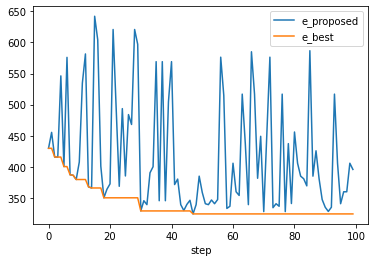

In [8]:
data.plot(x="step", y=["e_proposed", "e_best"])

In [9]:
data

,step,e_proposed,e_best,x_proposed_0,x_proposed_1,x_proposed_2,x_proposed_3,x_proposed_4,x_proposed_5,x_proposed_6,...,x_best_0,x_best_1,x_best_2,x_best_3,x_best_4,x_best_5,x_best_6,x_best_7,x_best_8,x_best_9
0,0.0,429.799988,429.799988,0.0,1.0,2.0,3.0,4.0,5.0,6.0,...,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0
1,1.0,455.399994,429.799988,0.0,5.0,2.0,3.0,4.0,1.0,6.0,...,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0
2,2.0,415.700012,415.700012,0.0,1.0,6.0,3.0,4.0,5.0,2.0,...,0.0,1.0,6.0,3.0,4.0,5.0,2.0,7.0,8.0,9.0
3,3.0,415.700012,415.700012,0.0,1.0,6.0,3.0,2.0,5.0,4.0,...,0.0,1.0,6.0,3.0,2.0,5.0,4.0,7.0,8.0,9.0
4,4.0,546.200012,415.700012,0.0,6.0,1.0,3.0,2.0,5.0,4.0,...,0.0,1.0,6.0,3.0,2.0,5.0,4.0,7.0,8.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95.0,340.700012,324.299988,0.0,1.0,2.0,4.0,7.0,9.0,6.0,...,0.0,3.0,2.0,4.0,7.0,9.0,6.0,8.0,5.0,1.0
96,96.0,359.899994,324.299988,0.0,3.0,1.0,4.0,7.0,9.0,6.0,...,0.0,3.0,2.0,4.0,7.0,9.0,6.0,8.0,5.0,1.0
97,97.0,359.899994,324.299988,0.0,3.0,1.0,4.0,7.0,9.0,6.0,...,0.0,3.0,2.0,4.0,7.0,9.0,6.0,8.0,5.0,1.0
98,98.0,405.799988,324.299988,0.0,3.0,5.0,4.0,7.0,9.0,6.0,...,0.0,3.0,2.0,4.0,7.0,9.0,6.0,8.0,5.0,1.0


## Solve pair-swapping avec MIP solver

In [10]:
class PairSwapMetropolisHastingsSequenceOptimizer(MetropolisHastingsSequenceOptimizer):
    
    def __init__(
            self,
            items: int,
            objective: Callable,
            margins: Callable,
            temp: float = 1.,
            sampler = SASampler,
            seed: int = None,
    ):
        super().__init__(len(items), objective, temp, seed)
        
        # self.nx = self.nx // 2
        self._items = items
        
        self._sampler_cls = sampler
        self._sampler = None
        
        self._margins = margins
        self._sampler = sampler
        
        self._e_sample_p = None
        self._e_sample_c = None
        
    def initialize(self):
        super().initialize()
        self.clear_sampler()
    
    def clear_sampler(self):
        self._sampler = self._sampler_cls()
    
    def _get_separation_function(self):
        def sf(vol1, vol2):
            return self._margins(vol1, vol2)
        return sf
    
    def _prob(self, e):
        return np.exp(-1 * e / self.T)
    
    def calc_accept_prob(self, ec, ep):
        prob_ec = self._prob(ec)
        prob_ep = self._prob(ep)
        prob_sc = self._prob(self._e_sample_c)
        prob_sp = self._prob(self._e_sample_p)
        
        r = np.min([1, prob_ep * prob_sc / prob_ec * prob_sp])
        return r
    
    def sample(self, x, step):
        self.clear_sampler()
        # print("given x:", x)
        # print("step:", step)
        
        # prepare current queue
        current_queue = [self._items[xi] for xi in x]
        # print("original queue:")
        # [print(vol) for vol in self._items]
        # print("current queue:")
        # [print(vol) for vol in current_queue]
        
        # calc pair shift size
        shift_by_step = (step - 1) % 2
        # prepare separation func
        S = self._get_separation_function()
        
        # pairing
        indices_of_vol_in_current_queue = [[i, i+1] for i in range(shift_by_step, len(current_queue) - 1, 2)]
        # print("paired index:", indices_of_vol_in_current_queue)
        ks = [
            [current_queue[i], current_queue[j]]
            for i, j in indices_of_vol_in_current_queue
        ]
        # print("- "*30)
        # print("shift_by_step:", shift_by_step)
        # print("paired")
        # [
        #     [print(v) for v in vpair]
        #     for vpair in ks
        # ]
        
        # define variable X
        xs = Array.create("x", shape=len(ks), vartype="BINARY")
        # print(xs)
        
        # intra-pair cost
        e_in = Constraint(sum([
            S(vol1, vol2) * (1 - x) + S(vol2, vol1) * x
            for (vol1, vol2), x in zip(ks, xs)
        ]), "inner")
        e_total = e_in
        
        # convert iterator of var to list
        if len(xs) > 1:
            lxs = list(xs)
            # inter-pair cost
            e_ex = Constraint(sum([
                (S(j2, k2) - S(j2, k1)) * xk + (S(j1, k1) - S(j2, k1)) * xk + (S(j1, k2) - S(j2, k1)) * xj * xk
                for (j1, j2), (k1, k2), xj, xk in zip(ks[:-1], ks[1:], lxs[:-1], lxs[1:])
            ]), "external")
            # print(e_in)
            # print(e_ex)
            
            e_total = e_total + e_ex
        
        model = e_total.compile()
        qubo, bias = model.to_qubo()
        # print("qubo:")
        # print(qubo)
        
        # sample from qubo
        sampleset = self._sampler.sample_qubo(qubo)
        sol = sampleset.first
        
        # reconstruct queue from sampled solution by swapping
        xdict = sol.sample
        indices_of_queue_sampled = sum([
            indices_of_vol_in_current_queue[i][::-1]
            if xdict["x[{}]".format(i)] else indices_of_vol_in_current_queue[i]
            for i in range(len(ks))
        ], [])
        sampled_queue = [x[i] for i in indices_of_queue_sampled]
        
        self._e_sample_p = sol.energy + bias
        self._e_sample_c = bias
        
        # print("INDICES-CURRENT-QUEUE:", indices_of_vol_in_current_queue)
        # print("SAMPLED-QUEUE", sampled_queue)
        return_queue = np.asarray(x).copy()
        for inserted_id, insert_target_index in enumerate(sum(indices_of_vol_in_current_queue, [])):
            return_queue[insert_target_index] = sampled_queue[inserted_id]
        
        # print("LAST-QUEUE:", return_queue)
        return return_queue
        
    
algo = PairSwapMetropolisHastingsSequenceOptimizer(
    vols, obj, sep
)
# print(vols.to_dataframe())
# print(algo.nx)
# algo.initialize()
data_2 = algo.optimize(100, x_init=[3,2,1,0])

IndexError: index 4 is out of bounds for axis 1 with size 4

In [ ]:
cf.num = 20

In [ ]:
vols, obj = generate_scenario_and_obj(cf)
algo_1 = MetropolisHastingsSequenceOptimizer(len(vols), obj)
data_1 = algo_1.optimize(100)
algo_2 = PairSwapMetropolisHastingsSequenceOptimizer(
    vols, obj, sep
)
data_2 = algo_2.optimize(100)

In [ ]:
fig, ax = plt.subplots()
data_1.plot("step", "e_best", ax=ax, label="random")
data_2.plot("step", "e_best", ax=ax, label="pair-wise")

### test

In [ ]:
sampler = SASampler()

In [ ]:
sampler.sample_qubo({
    ("x[1]", "x[1]"): -1,
    ("x[1]", "x[2]"): 10,
    ("x[2]", "x[2]"): -1,
})